# Step 2 — WS-A: Project Archetypes (the spine)
We label every project by the **kind of job** it is, two independent ways, and
compare them. See methodology §4 for the "recipe / proportions" intuition.

- **Rule-based** = codify CSI's 5 named archetypes as thresholds.
- **Discovered** = PCA + K-means on the scale-free material recipe — let the
  data find its own groups.

The comparison (do they agree?) is itself a finding.

In [1]:
from pathlib import Path
import warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=RuntimeWarning)  # spurious BLAS matmul noise on this machine
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 40)

# --- Absolute paths (edit BASE if you move the project) -----------------------
BASE   = Path("/Users/t/Library/Mobile Documents/com~apple~CloudDocs/00 MSBA + Coding/00_summer 2026/00_CSI_ELP/01_Summer_2026")
MASTER = BASE / "2026-06-03_csi_bid_master.csv"          # raw source (read-only)
OUT    = BASE / "06_sweetspot" / "outputs"               # intermediates + figures
OUT.mkdir(parents=True, exist_ok=True)
MAT = ["MIX_TN","GRADE_CY","BASE_TN","SHLDR_TN","MILL_SY","CRUSH_TN","STOCK_TN"]
print("paths OK |", MASTER.name, "exists:", MASTER.exists())

paths OK | 2026-06-03_csi_bid_master.csv exists: True


In [2]:
df = pd.read_csv(OUT / "2026-06-04_project_base.csv")
PROP = ["prop_"+m for m in MAT]
print(df.shape, "| quantity-complete:", int(df["has_quantity"].sum()))

(1591, 46) | quantity-complete: 1376


### (1) Rule-based — CSI's five archetypes
Priority order matters: we check **complexity** first (CSI's claimed edge), then
**volume**, then **composition**. Projects with no quantities get `Unknown/NoQty`.

In [3]:
def rule_archetype(r):
    if not r["has_quantity"]: return "Unknown/NoQty"
    box, nmat = bool(r["BOX"]), r["n_mat_types"]
    g = lambda k: r[k] if pd.notna(r[k]) else 0
    mix = g("MIX_TN_num"); pg=g("prop_GRADE_CY"); pb=g("prop_BASE_TN"); ps=g("prop_SHLDR_TN"); pm=g("prop_MIX_TN")
    if box or nmat >= 5:            return "Complex/Messy"      # multi-trade / culvert
    if mix > 10_000:               return "Large Volume"       # high asphalt tonnage
    if pg >= 0.50:                 return "Earthwork Heavy"     # grade-dominated
    if (pb+ps) >= 0.60 and pm<0.20:return "Shoulder/Base Only" # base/shoulder, little asphalt
    return "Standard Paving"                                   # default mill-and-fill
df["rule_archetype"] = df.apply(rule_archetype, axis=1)
df["rule_archetype"].value_counts()

rule_archetype
Standard Paving       484
Large Volume          319
Earthwork Heavy       262
Complex/Messy         227
Unknown/NoQty         215
Shoulder/Base Only     84
Name: count, dtype: int64

### (2) Discovered — PCA + K-means on the recipe
We cluster on the **proportion** vector only (shape, not scale), standardized so
no single material dominates the distance. We sweep k=3..6 and pick the best
**silhouette** (cluster separation, higher = better), then check stability by
re-running with a different random seed (**ARI ≈ 1.0** = identical clusters).

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
qc = df[df["has_quantity"]].copy()
Xs = StandardScaler().fit_transform(qc[PROP].fillna(0.0).values)
for k in range(3,7):
    km = KMeans(k, n_init=10, random_state=42).fit(Xs)
    print(f"k={k}  silhouette={silhouette_score(Xs, km.labels_):.3f}")

k=3  silhouette=0.433


k=4  silhouette=0.438


k=5  silhouette=0.515


k=6  silhouette=0.569


In [5]:
K = 6                       # chosen: best silhouette
km  = KMeans(K, n_init=25, random_state=42).fit(Xs)
km2 = KMeans(K, n_init=25, random_state=7 ).fit(Xs)
qc["cluster_id"] = km.labels_
print("re-seed stability (ARI):", round(adjusted_rand_score(km.labels_, km2.labels_), 3), "(~1.0 = stable)")

re-seed stability (ARI): 0.996 (~1.0 = stable)


### Name each cluster by its dominant material, inspect the profiles

In [6]:
prof = qc.groupby("cluster_id")[PROP].mean().round(3)
prof.insert(0, "n", qc.groupby("cluster_id").size())
dom = qc.groupby("cluster_id")[PROP].mean().idxmax(axis=1).str.replace("prop_","")
name_map = {cid: f"C{cid}:{dom[cid]}-dom" for cid in dom.index}
qc["cluster_label"] = qc["cluster_id"].map(name_map)
print(name_map); prof

{0: 'C0:GRADE_CY-dom', 1: 'C1:BASE_TN-dom', 2: 'C2:MIX_TN-dom', 3: 'C3:CRUSH_TN-dom', 4: 'C4:SHLDR_TN-dom', 5: 'C5:MILL_SY-dom'}


,n,prop_MIX_TN,prop_GRADE_CY,prop_BASE_TN,prop_SHLDR_TN,prop_MILL_SY,prop_CRUSH_TN,prop_STOCK_TN
cluster_id,,,,,,,,
0,355,0.046,0.807,0.128,0.004,0.011,0.000,0.004
1,242,0.159,0.166,0.534,0.012,0.110,0.000,0.019
2,218,0.764,0.074,0.062,0.059,0.041,0.000,0.001
3,7,0.000,0.000,0.000,0.000,0.000,1.000,0.000
4,132,0.171,0.014,0.029,0.750,0.031,0.000,0.005
5,422,0.105,0.022,0.079,0.011,0.778,0.001,0.003


### Do CSI's labels and the data's clusters agree?
**Adjusted Rand Index (ARI)** measures label agreement (1 = identical, 0 =
random). A **low** value here is the interesting result: CSI's taxonomy blends
*scale* and *complexity* into a *shape* question, so the data cuts differently.

In [7]:
ct = pd.crosstab(qc["rule_archetype"], qc["cluster_label"])
ari = adjusted_rand_score(qc["rule_archetype"].astype("category").cat.codes, qc["cluster_id"])
print("ARI (rule vs discovered):", round(ari,3), " -> low = they disagree (a finding)")
ct

ARI (rule vs discovered): 0.251  -> low = they disagree (a finding)


cluster_label,C0:GRADE_CY-dom,C1:BASE_TN-dom,C2:MIX_TN-dom,C3:CRUSH_TN-dom,C4:SHLDR_TN-dom,C5:MILL_SY-dom
rule_archetype,,,,,,
Complex/Messy,74,19,17,0,30,87
Earthwork Heavy,251,11,0,0,0,0
Large Volume,26,12,106,0,63,112
Shoulder/Base Only,0,52,0,0,32,0
Standard Paving,4,148,95,7,7,223


### Visualize the material space (PCA to 2-D)

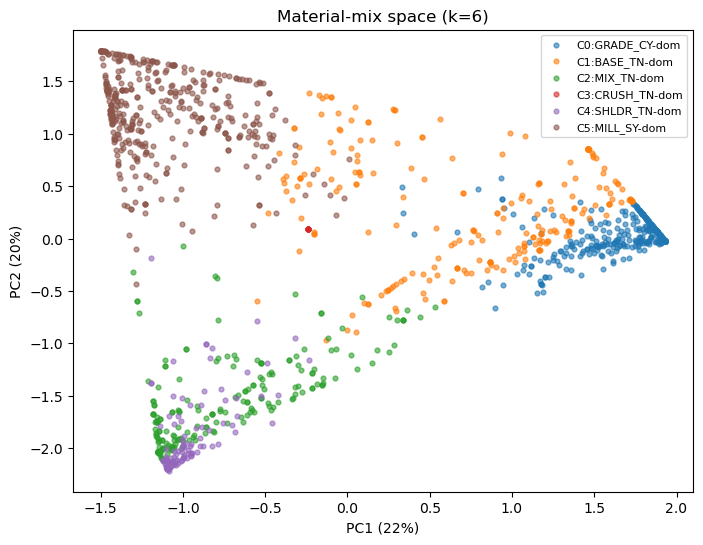

In [8]:
p2 = PCA(2, random_state=42).fit(Xs); XY = p2.transform(Xs); ev = p2.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(8,6))
for cid in sorted(qc["cluster_id"].unique()):
    m = (qc["cluster_id"]==cid).values
    ax.scatter(XY[m,0], XY[m,1], s=12, alpha=.6, label=name_map[cid])
ax.set_xlabel(f"PC1 ({ev[0]*100:.0f}%)"); ax.set_ylabel(f"PC2 ({ev[1]*100:.0f}%)")
ax.set_title("Material-mix space (k=6)"); ax.legend(fontsize=8); plt.show()

In [9]:
# save labels for both definitions back onto every project
out = (df[["Contract_Id","rule_archetype"]]
       .merge(qc[["Contract_Id","cluster_id","cluster_label"]], on="Contract_Id", how="left"))
out.to_csv(OUT / "2026-06-04_project_archetypes.csv", index=False)
prof.to_csv(OUT / "2026-06-04_archetype_cluster_profiles.csv")
print("saved archetypes for", len(out), "projects")

saved archetypes for 1591 projects


**Takeaway:** six natural single-material-dominant shapes, very stable
(ARI 0.996), agreeing only weakly with CSI's named taxonomy (ARI ≈ 0.25). Both
labelings are saved; downstream we use `rule_archetype` for the client-facing
story and the clusters for cross-checks.